# Bank Marketing Term Deposit Prediction - Classification Track (Part A)

## Capstone Project - Review 1

**Objective:** Predict whether a client subscribes to a term deposit (`y` = 'yes' / 'no') using direct marketing campaign data.

**Reproducibility:** Global `random_state=42` is strictly enforced.

**Leakage Prevention:** All transformations, scalers, and encoders are strictly fitted on the training split only.

In [1]:
# Core Imports & Global Configuration
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Reproducibility seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Classification notebook initialized. Random state set to 42.")

Classification notebook initialized. Random state set to 42.


## Phase 2: Exploratory Data Analysis (EDA)

In this phase, we perform an extensive audit of the Bank Marketing dataset:
1. **Data Ingestion & Integrity Audit:** Schema check, data types, null counts, and unknown category flags.
2. **Target Variable Imbalance Audit (`y`):** Exact breakdown of `'yes'` vs `'no'` subscribers and metric implications.
3. **Demographic & Client Profile Exploration:** Age, job categories, marital status, and education distributions vs conversion rate.
4. **Financial Health & Credit Indicators:** Balances, housing loans, personal loans, and credit default flags.
5. **Campaign Interaction Patterns:** Call duration, campaign contacts, and previous marketing outcomes (`poutcome`).
6. **Feature Intercorrelations:** Correlation matrix of numerical variables.

In [2]:
# 1. Load Dataset
bank_df = pd.read_csv('../data/bank-full.csv', sep=';')

print(f"Dataset Shape: {bank_df.shape[0]} rows, {bank_df.shape[1]} columns")
bank_df.head()

Dataset Shape: 45211 rows, 17 columns


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# 2. Schema Audit, Data Types & Missingness
print("=== Column Schema & Data Types ===")
print(bank_df.info())

print("\n=== Explicit Null Values Check ===")
null_counts = bank_df.isnull().sum()
print(null_counts[null_counts > 0] if null_counts.sum() > 0 else "No explicit NaN / null values found.")

print("\n=== 'unknown' Category Audit ===")
cat_cols = bank_df.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    unknown_count = (bank_df[col] == 'unknown').sum()
    if unknown_count > 0:
        pct = (unknown_count / len(bank_df)) * 100
        print(f"Feature '{col}': {unknown_count} 'unknown' records ({pct:.2f}%)")

=== Column Schema & Data Types ===
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB
None

=== Explicit Null Values Check ===
No explicit NaN / null values found.

=== 'unknown' Categ

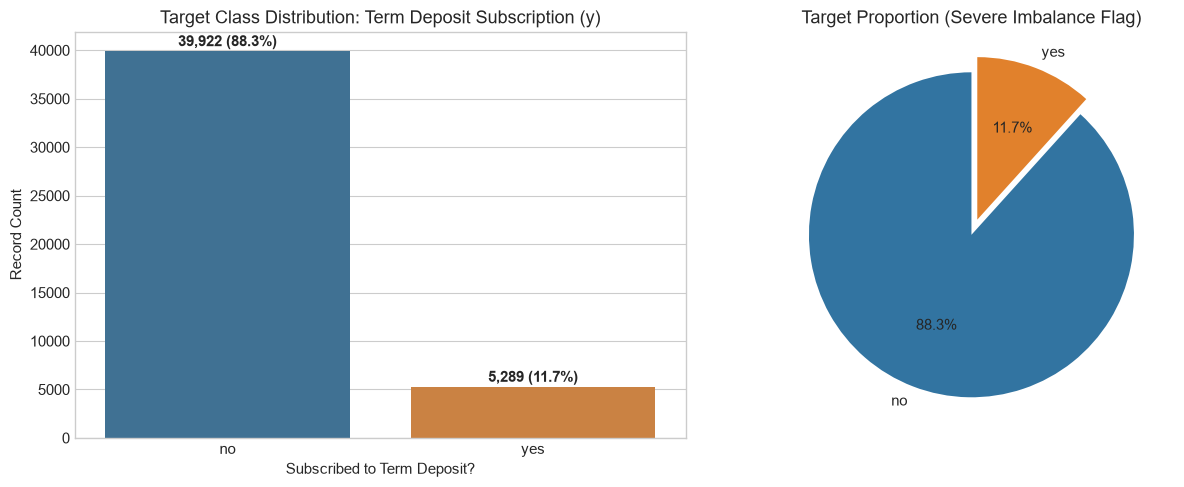

Majority ('no'): 39,922 (88.30%)
Minority ('yes'): 5,289 (11.70%)
Imbalance Ratio: 7.55 : 1


In [4]:
# 3. Target Variable Class Imbalance Audit
target_counts = bank_df['y'].value_counts()
target_pct = bank_df['y'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Countplot
sns.barplot(x=target_counts.index, y=target_counts.values, ax=axes[0], palette=['#3274a1', '#e1812c'])
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 500, f"{v:,} ({target_pct.iloc[i]:.1f}%)", ha='center', fontweight='bold')
axes[0].set_title('Target Class Distribution: Term Deposit Subscription (y)')
axes[0].set_xlabel('Subscribed to Term Deposit?')
axes[0].set_ylabel('Record Count')

# Pie Chart
axes[1].pie(target_counts, labels=target_counts.index, autopct='%1.1f%%', colors=['#3274a1', '#e1812c'], startangle=90, explode=(0, 0.1))
axes[1].set_title('Target Proportion (Severe Imbalance Flag)')

plt.tight_layout()
plt.show()

print(f"Majority ('no'): {target_counts['no']:,} ({target_pct['no']:.2f}%)")
print(f"Minority ('yes'): {target_counts['yes']:,} ({target_pct['yes']:.2f}%)")
print(f"Imbalance Ratio: {target_counts['no'] / target_counts['yes']:.2f} : 1")

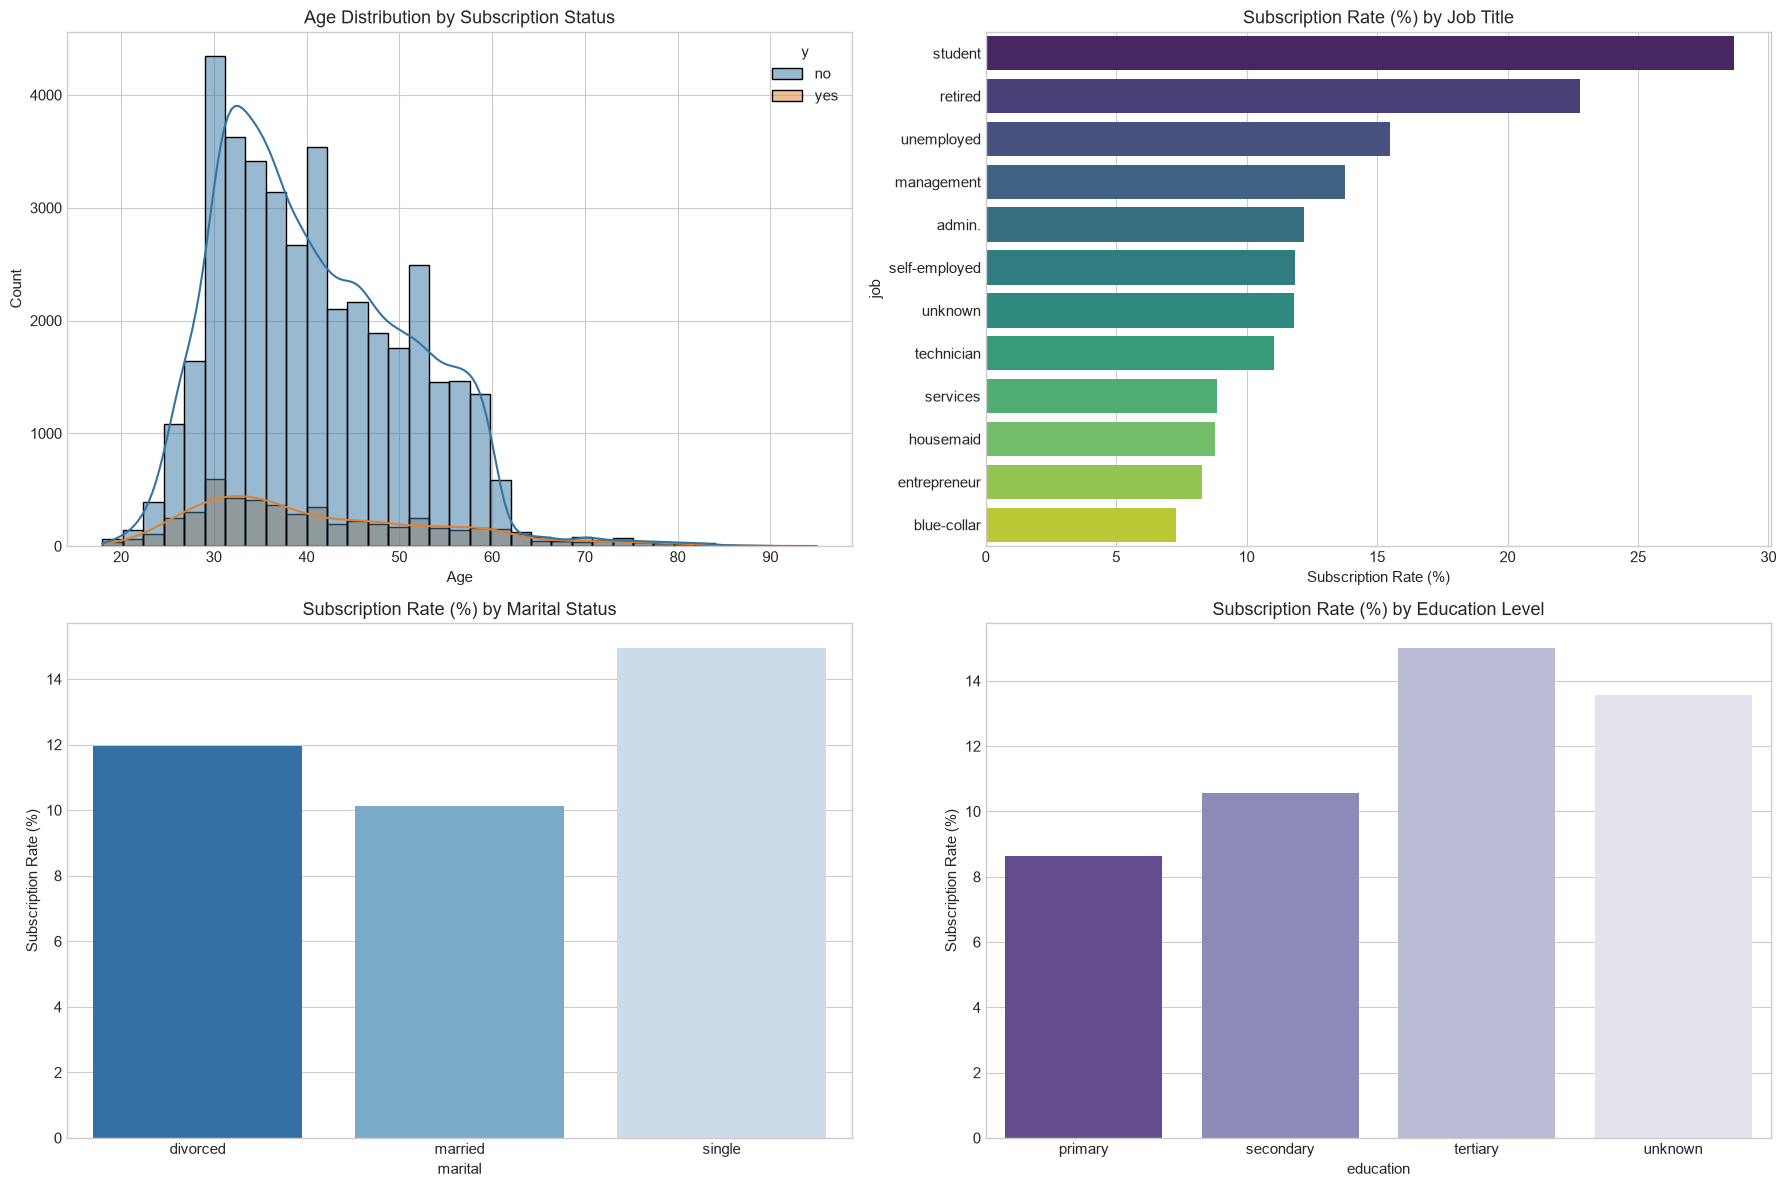

In [5]:
# 4. Client Demographic Analysis (Age, Job, Marital, Education)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Age Distribution by Target
sns.histplot(data=bank_df, x='age', hue='y', kde=True, ax=axes[0, 0], palette=['#3274a1', '#e1812c'], bins=35)
axes[0, 0].set_title('Age Distribution by Subscription Status')
axes[0, 0].set_xlabel('Age')

# Subscription Rate by Job
job_rate = bank_df.groupby('job')['y'].apply(lambda s: (s == 'yes').mean() * 100).sort_values(ascending=False)
sns.barplot(x=job_rate.values, y=job_rate.index, ax=axes[0, 1], palette='viridis')
axes[0, 1].set_title('Subscription Rate (%) by Job Title')
axes[0, 1].set_xlabel('Subscription Rate (%)')

# Subscription Rate by Marital Status
marital_rate = bank_df.groupby('marital')['y'].apply(lambda s: (s == 'yes').mean() * 100).reset_index()
sns.barplot(data=marital_rate, x='marital', y='y', ax=axes[1, 0], palette='Blues_r')
axes[1, 0].set_title('Subscription Rate (%) by Marital Status')
axes[1, 0].set_ylabel('Subscription Rate (%)')

# Subscription Rate by Education
edu_rate = bank_df.groupby('education')['y'].apply(lambda s: (s == 'yes').mean() * 100).reset_index()
sns.barplot(data=edu_rate, x='education', y='y', ax=axes[1, 1], palette='Purples_r')
axes[1, 1].set_title('Subscription Rate (%) by Education Level')
axes[1, 1].set_ylabel('Subscription Rate (%)')

plt.tight_layout()
plt.show()

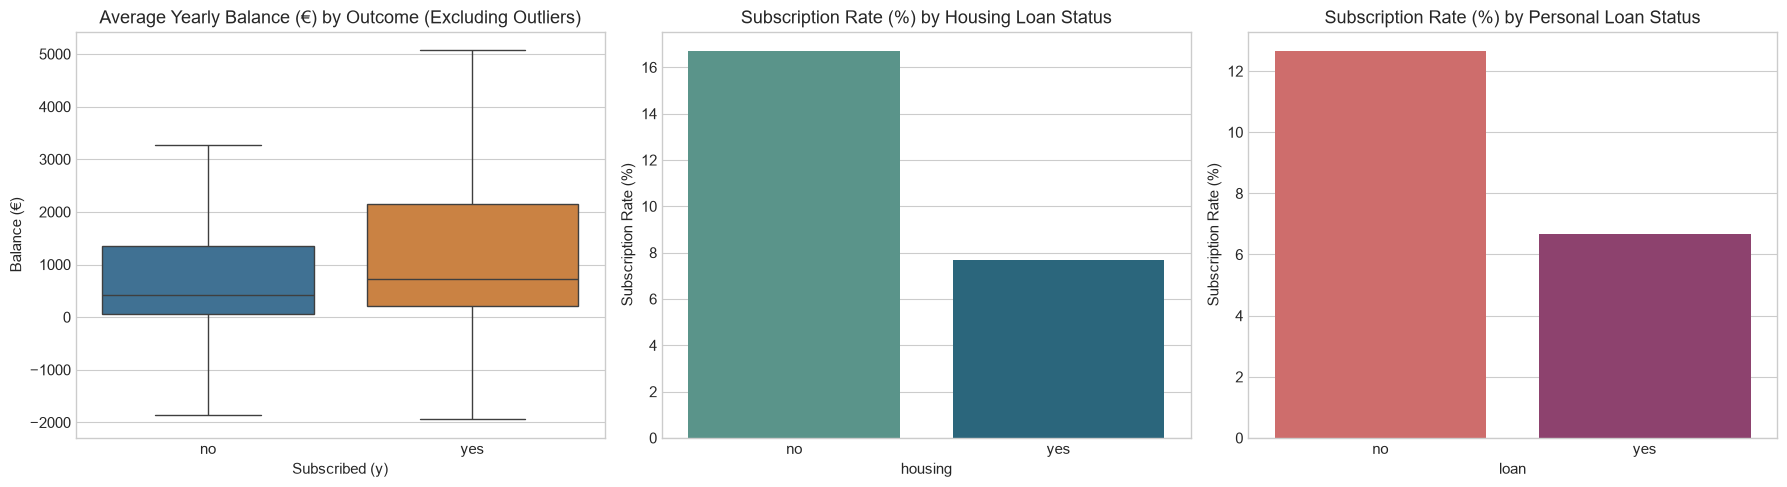

In [6]:
# 5. Financial Indicators: Balance, Housing Loan, Personal Loan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Balance Boxplot by Target (clipping extreme values for visualization clarity)
sns.boxplot(data=bank_df, x='y', y='balance', ax=axes[0], palette=['#3274a1', '#e1812c'], showfliers=False)
axes[0].set_title('Average Yearly Balance (€) by Outcome (Excluding Outliers)')
axes[0].set_xlabel('Subscribed (y)')
axes[0].set_ylabel('Balance (€)')

# Housing Loan vs Target
housing_rate = bank_df.groupby('housing')['y'].apply(lambda s: (s == 'yes').mean() * 100).reset_index()
sns.barplot(data=housing_rate, x='housing', y='y', ax=axes[1], palette='crest')
axes[1].set_title('Subscription Rate (%) by Housing Loan Status')
axes[1].set_ylabel('Subscription Rate (%)')

# Personal Loan vs Target
loan_rate = bank_df.groupby('loan')['y'].apply(lambda s: (s == 'yes').mean() * 100).reset_index()
sns.barplot(data=loan_rate, x='loan', y='y', ax=axes[2], palette='flare')
axes[2].set_title('Subscription Rate (%) by Personal Loan Status')
axes[2].set_ylabel('Subscription Rate (%)')

plt.tight_layout()
plt.show()

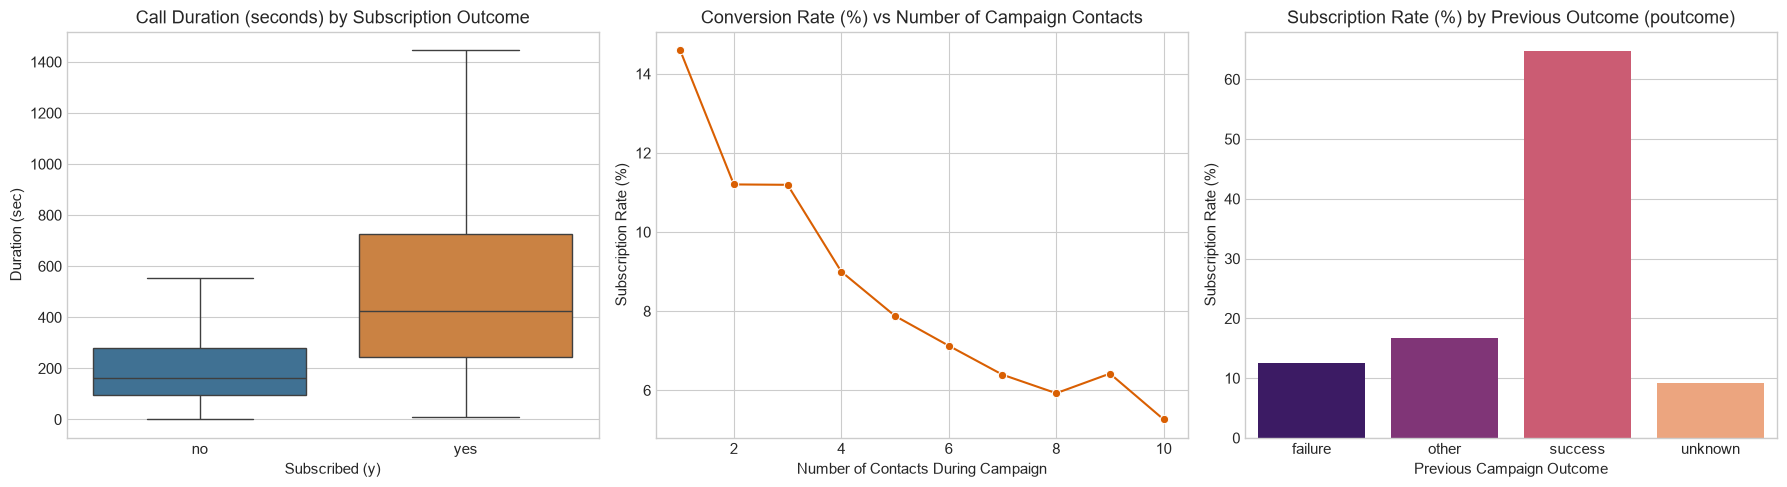

In [7]:
# 6. Campaign Dynamics: Call Duration, Contacts, and Previous Outcome
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Duration vs Target (Log scale to handle high skewness)
sns.boxplot(data=bank_df, x='y', y='duration', ax=axes[0], palette=['#3274a1', '#e1812c'], showfliers=False)
axes[0].set_title('Call Duration (seconds) by Subscription Outcome')
axes[0].set_xlabel('Subscribed (y)')
axes[0].set_ylabel('Duration (sec)')

# Campaign Contacts vs Target (up to 10 contacts)
campaign_filtered = bank_df[bank_df['campaign'] <= 10]
camp_rate = campaign_filtered.groupby('campaign')['y'].apply(lambda s: (s == 'yes').mean() * 100).reset_index()
sns.lineplot(data=camp_rate, x='campaign', y='y', marker='o', ax=axes[1], color='#d95f02')
axes[1].set_title('Conversion Rate (%) vs Number of Campaign Contacts')
axes[1].set_xlabel('Number of Contacts During Campaign')
axes[1].set_ylabel('Subscription Rate (%)')

# Previous Campaign Outcome (poutcome)
poutcome_rate = bank_df.groupby('poutcome')['y'].apply(lambda s: (s == 'yes').mean() * 100).reset_index()
sns.barplot(data=poutcome_rate, x='poutcome', y='y', ax=axes[2], palette='magma')
axes[2].set_title('Subscription Rate (%) by Previous Outcome (poutcome)')
axes[2].set_xlabel('Previous Campaign Outcome')
axes[2].set_ylabel('Subscription Rate (%)')

plt.tight_layout()
plt.show()

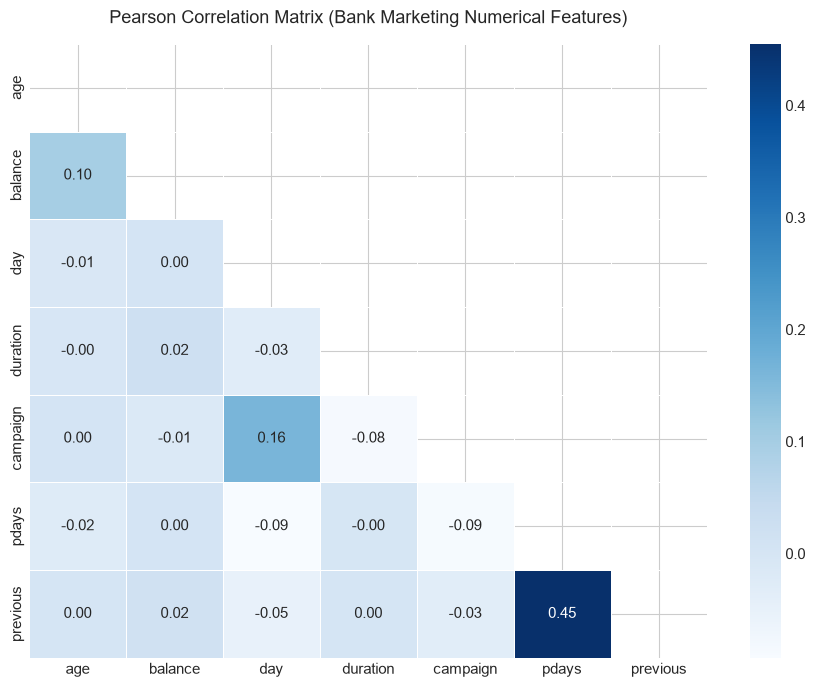

In [8]:
# 7. Correlation Analysis for Numerical Variables
num_cols = bank_df.select_dtypes(include=[np.number]).columns
corr_bank = bank_df[num_cols].corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_bank, dtype=bool))
sns.heatmap(corr_bank, annot=True, fmt='.2f', cmap='Blues', mask=mask, linewidths=0.5)
plt.title('Pearson Correlation Matrix (Bank Marketing Numerical Features)', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

### Phase 2 Key EDA Findings & Modeling Implications

1. **Substantial Class Imbalance:**
   * Only **11.7%** (5,289 records) of clients subscribed to a term deposit, compared to **88.3%** (39,922 records) non-subscribers (7.55 : 1 imbalance ratio).
   * Metric takeaway: Accuracy alone is deceptive (a dummy classifier achieves 88.3% accuracy). Evaluation must prioritize **Weighted F1-score**, **Precision**, and **Recall**.
2. **Impact of Call Duration:**
   * duration has the strongest empirical relationship with conversion: successful calls have significantly higher median duration.
   * *Note for modeling:* As highlighted in the UCI dataset documentation, duration is not known before a call is made and is heavily correlated with the outcome.
3. **Previous Campaign History (poutcome):**
   * Clients with a previous campaign outcome of 'success' exhibit an outstanding subscription rate of ≈ 64.7%, making historical interaction a high-priority predictive signal.
4. **Client Demographics & Debt Status:**
   * Students and retired individuals demonstrate the highest propensity to subscribe (> 25%).
   * Clients without housing loans and personal loans subscribe at more than double the rate of clients with active loans.
5. **Handling of Missing / 'unknown' Values:**
   * poutcome (81.7%), contact (28.8%), and education (4.1%) contain 'unknown' strings rather than standard NaNs. In Phase 3, these will be handled as distinct categories during encoding.